# Mathematics Transformer

### Using this kind of function helps in converting data pdf(probablity density function) in Normal distribution
### Some of the algorithm needs to have normal distribution for performing good like logistic regrssion,linear regressiom etc. 

### Some of the way to find weather data is normal distributed are
### - sns.histplot(,kde=True)
### - sns.kdeplot()
### - pd.skew() If it is 0 then its normal distributed if other value then not
### - QQplot

## How to plot QQplt

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df1=sns.load_dataset("iris")

In [3]:
df1.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
temp=sorted(df1['sepal_length'].tolist())
len(temp)

150

In [5]:
y_quant=[]
for i in range(1,101):
    y_quant.append(np.percentile(temp,i))

In [6]:
samples=np.random.normal(loc=0,scale=1,size=1000)#mean=0,standard deviation= 1,data_size=1000

In [7]:
x_quant=[]
for i in range(1,101):
    x_quant.append(np.percentile(samples,i))

<Axes: >

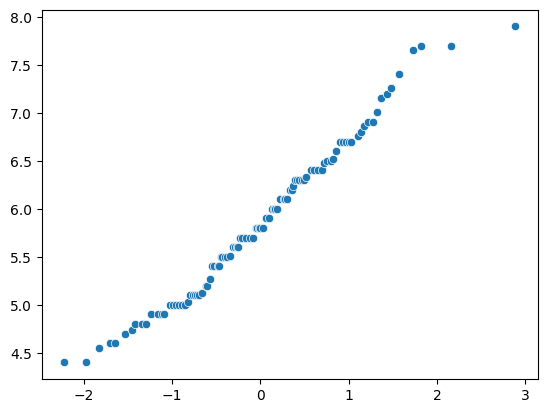

In [8]:
sns.scatterplot(x=x_quant,y=y_quant)

In [9]:
import statsmodels.api as sm

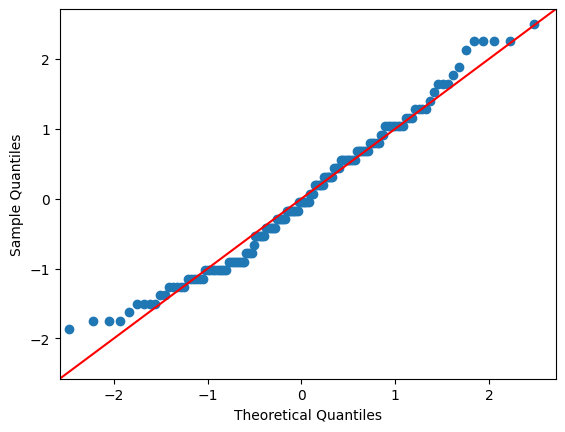

In [10]:
fig=sm.qqplot(df1["sepal_length"],line="45",fit=True)# dataset,line(which line to choose),

In [11]:
import scipy.stats as stats

Text(0.5, 1.0, 'QQPlot')

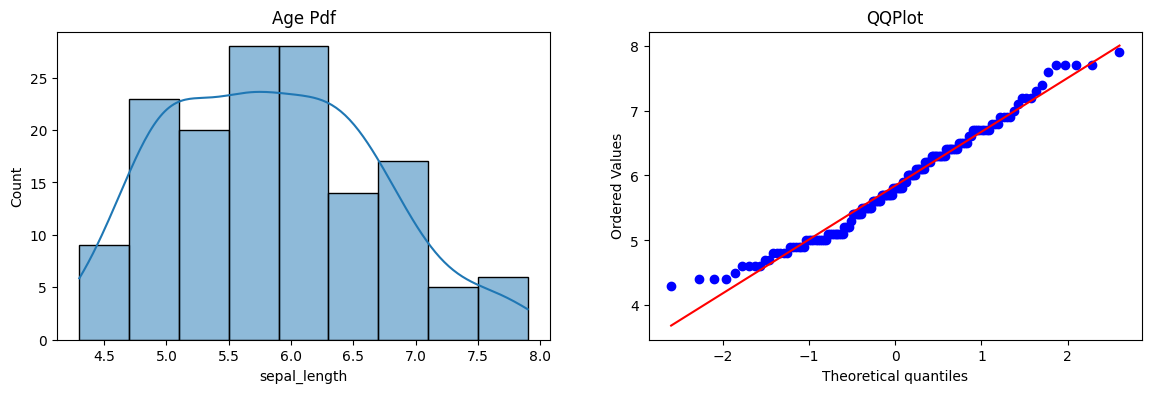

In [12]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(df1["sepal_length"],kde=True)
plt.title("Age Pdf")

plt.subplot(122)
stats.probplot(df1["sepal_length"],dist="norm",plot=plt)#Using the scipy.stats
plt.title("QQPlot")

## How to interpret QQplot

https://www.statsmodels.org/stable/generated/statsmodels.graphics.gofplots.qqplot.html

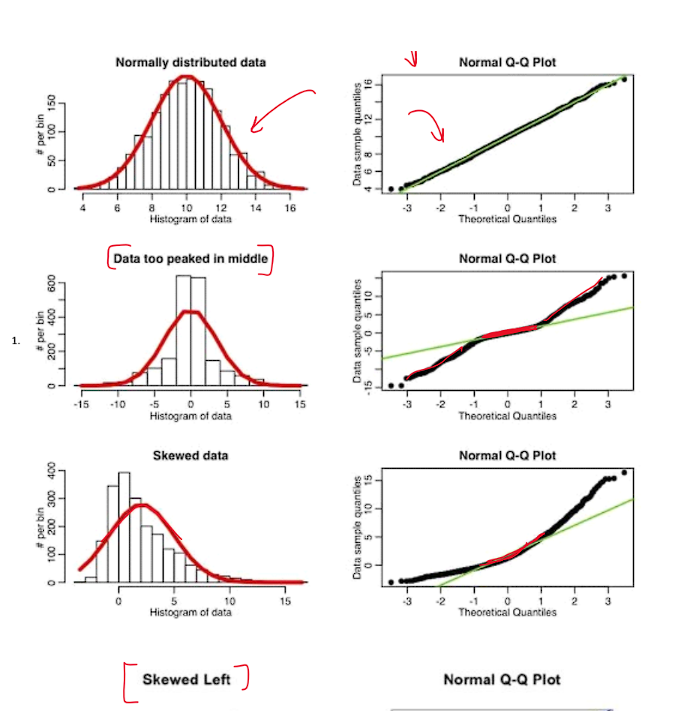
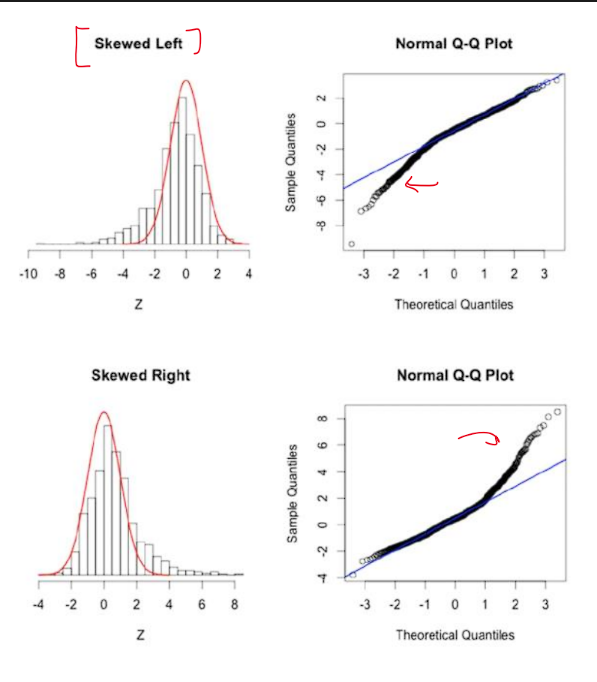
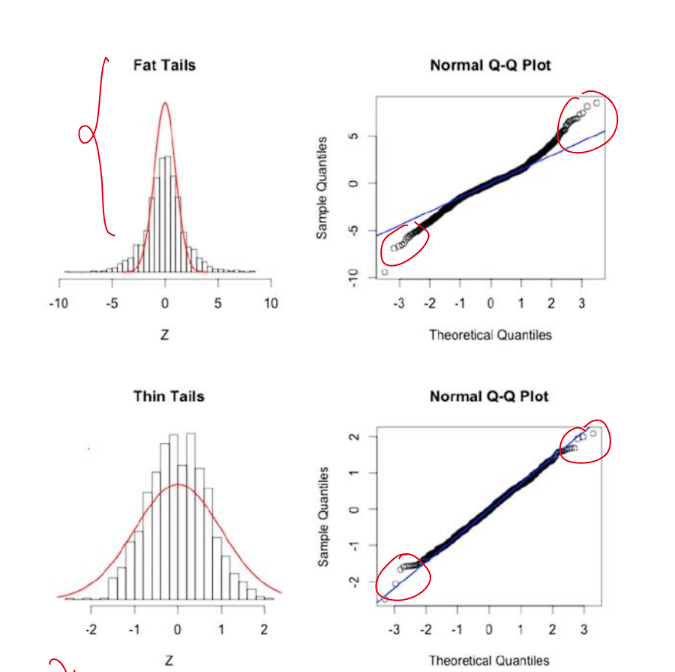

In [13]:
import scipy.stats as stats
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer

In [14]:
df=pd.read_csv("train.csv",usecols=["Age","Fare","Survived"])

In [15]:
df["Age"].fillna(df["Age"].mean(),inplace=True)

C:\Users\prana\AppData\Local\Temp\ipykernel_9824\2595122914.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Age"].fillna(df["Age"].mean(),inplace=True)


In [16]:
df.sample(5)

,Survived,Age,Fare
887,1,19.0,30.00
353,0,25.0,17.80
85,1,33.0,15.85
217,0,42.0,27.00
782,0,29.0,30.00


In [17]:
x=df.iloc[:,1:3]
y=df.iloc[:,0]

In [18]:
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.3,
    random_state=0
)

Text(0.5, 1.0, 'QQPlot')

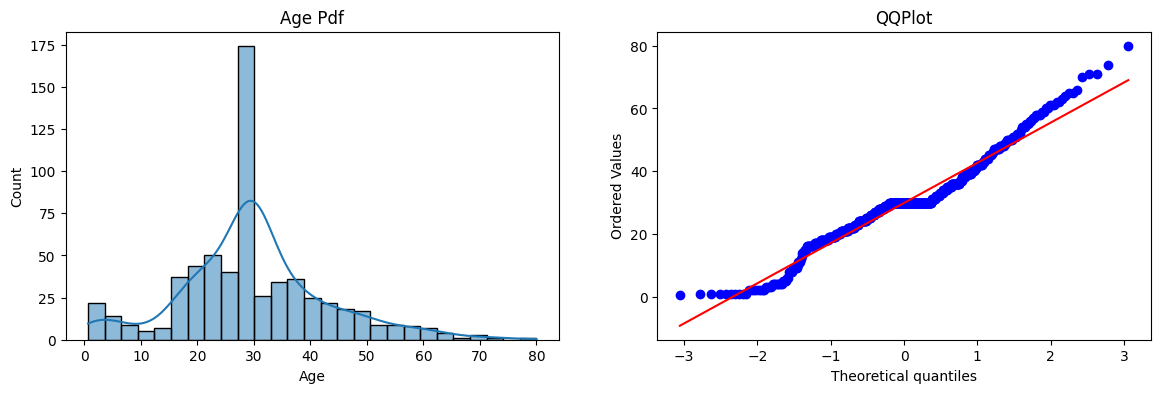

In [19]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(x_train["Age"],kde=True)
plt.title("Age Pdf")

plt.subplot(122)
stats.probplot(x_train["Age"],dist="norm",plot=plt)
plt.title("QQPlot")

### Here this data is not completly normal distribution but little normal distribution

Text(0.5, 1.0, 'QQPlot')

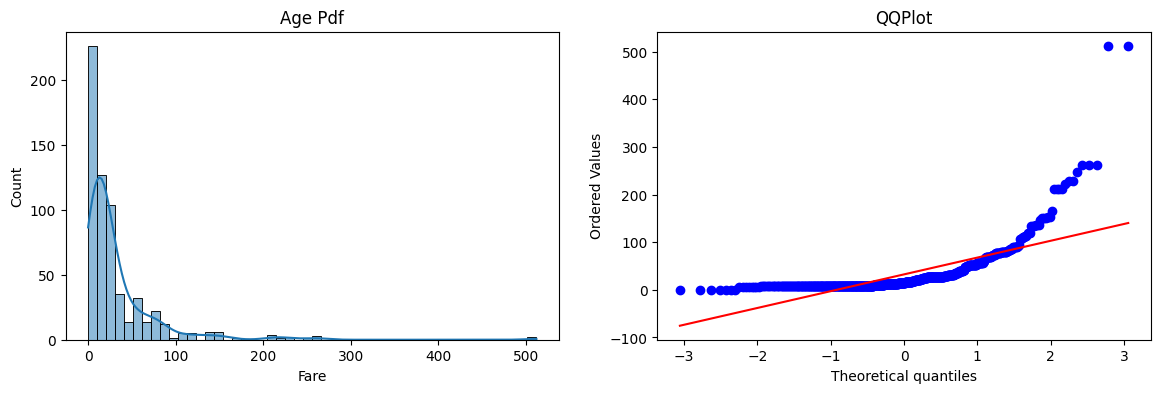

In [20]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(x_train["Fare"],kde=True)
plt.title("Age Pdf")

plt.subplot(122)
stats.probplot(x_train["Fare"],dist="norm",plot=plt)
plt.title("QQPlot")

### Right Skewed data is this so here we use ***Log Transform***
https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.FunctionTransformer.html#sklearn.preprocessing.FunctionTransformer

In [21]:
clf=LogisticRegression()
dtc=DecisionTreeClassifier()

In [22]:
clf.fit(x_train,y_train)
dtc.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [23]:
y_pred=clf.predict(x_test)
y_pred1=dtc.predict(x_test)

In [24]:
print(f"LogisticRegression= {accuracy_score(y_test,y_pred)}")
print(f"DecisionTreeClassifier= {accuracy_score(y_test,y_pred1)}")

LogisticRegression= 0.6865671641791045
DecisionTreeClassifier= 0.6604477611940298


### Without transform we get this accuracy 

In [25]:
trf=FunctionTransformer(func=np.log1p)

In [26]:
x_train_transformed=trf.fit_transform(x_train)
x_test_transformed=trf.fit_transform(x_test)

In [27]:
clf=LogisticRegression()
dtc=DecisionTreeClassifier()

In [28]:
clf.fit(x_train_transformed,y_train)
dtc.fit(x_train_transformed,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [29]:
y_pred_tranformed=clf.predict(x_test_transformed)
y_pred1_transformed=dtc.predict(x_test_transformed)

In [30]:
print(f"LogisticRegression= {accuracy_score(y_test,y_pred_tranformed)}")
print(f"DecisionTreeClassifier= {accuracy_score(y_test,y_pred1_transformed)}")

LogisticRegression= 0.7126865671641791
DecisionTreeClassifier= 0.6791044776119403


### After applying the log transform to all column we see that decision tree was not affected by that much but logistic regression did improve

In [31]:
x_transformed=trf.fit_transform(x)
clf=LogisticRegression()
dtc=DecisionTreeClassifier()
print("LR",np.mean(cross_val_score(clf,x_transformed,y,scoring="accuracy",cv=10)))
print("DTC",np.mean(cross_val_score(dtc,x_transformed,y,scoring="accuracy",cv=10)))

LR 0.678027465667915
DTC 0.6543445692883896


### After running 10 times and cross validating with with mean we get this result

Text(0.5, 1.0, 'After Log transform')

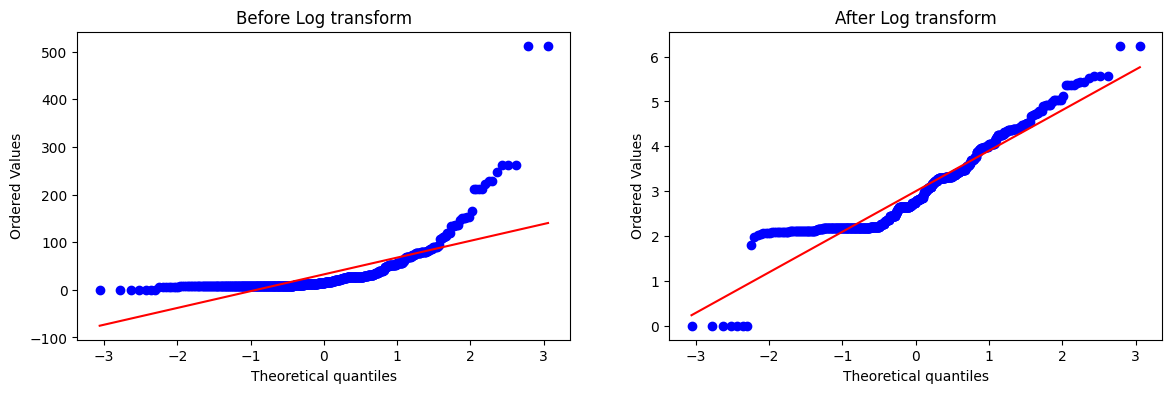

In [32]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(x_train["Fare"],dist="norm",plot=plt)
plt.title("Before Log transform")

plt.subplot(122)
stats.probplot(x_train_transformed["Fare"],dist="norm",plot=plt)
plt.title("After Log transform")

### As we can see here the normal looks much better after log transform

Text(0.5, 1.0, 'After Log transform')

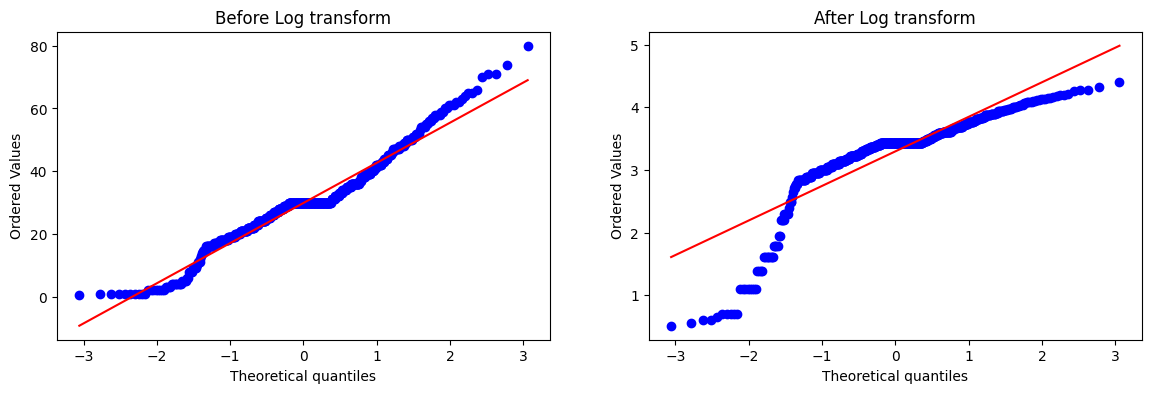

In [33]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(x_train["Age"],dist="norm",plot=plt)
plt.title("Before Log transform")

plt.subplot(122)
stats.probplot(x_train_transformed["Age"],dist="norm",plot=plt)
plt.title("After Log transform")

### But for this column(Age) the transform ruined it 

In [34]:
trf2=ColumnTransformer([("log",FunctionTransformer(np.log1p),["Fare"])],remainder="passthrough")

### Now applying log transform for only Fare

In [35]:
# trf2=FunctionTransformer(func=np.log1p)

In [36]:
x_train_transformed2=trf2.fit_transform(x_train)
x_test_transformed2=trf2.fit_transform(x_test)

In [37]:
clf=LogisticRegression()
dtc=DecisionTreeClassifier()

In [38]:
clf.fit(x_train_transformed2,y_train)
dtc.fit(x_train_transformed2,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [39]:
y_pred_tranformed2=clf.predict(x_test_transformed2)
y_pred1_transformed2=dtc.predict(x_test_transformed2)

In [40]:
print(f"LogisticRegression= {accuracy_score(y_test,y_pred_tranformed2)}")
print(f"DecisionTreeClassifier= {accuracy_score(y_test,y_pred1_transformed2)}")

LogisticRegression= 0.6977611940298507
DecisionTreeClassifier= 0.6753731343283582


### In this case as we can see that accuracy decreased idk why but in many or we can say some other cases our accuracy can increase and also we observe there is no change in Decision Tree Algorithm

In [41]:
x_transformed2=trf2.fit_transform(x)
clf=LogisticRegression()
dtc=DecisionTreeClassifier()
print("LR",np.mean(cross_val_score(clf,x_transformed2,y,scoring="accuracy",cv=10)))
print("DTC",np.mean(cross_val_score(dtc,x_transformed2,y,scoring="accuracy",cv=10)))

LR 0.6712609238451936
DTC 0.6599375780274657


### After running 10 times and cross validating with with mean we get this result

## This is the function used for other type of function transformer like sqr root,reciprocal etc.

In [48]:
def apply_transform(transform):
    x=df.iloc[:,1:3]
    y=df.iloc[:,0]
    trf=ColumnTransformer([('transform',FunctionTransformer(transform),["Fare"])],
                         remainder="passthrough")
    
    x_trans=trf.fit_transform(x)
    clf=LogisticRegression()
    print("Accuracy: ",np.mean(cross_val_score(clf,x_trans,y,scoring="accuracy",cv=10)))
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    stats.probplot(x_train["Fare"],dist="norm",plot=plt)
    plt.title("Before Log transform")

    plt.subplot(122)
    stats.probplot(x_trans[:,0],dist="norm",plot=plt)
    plt.title("After Log transform")

## Reciprocal Transform

Accuracy:  0.61729088639201


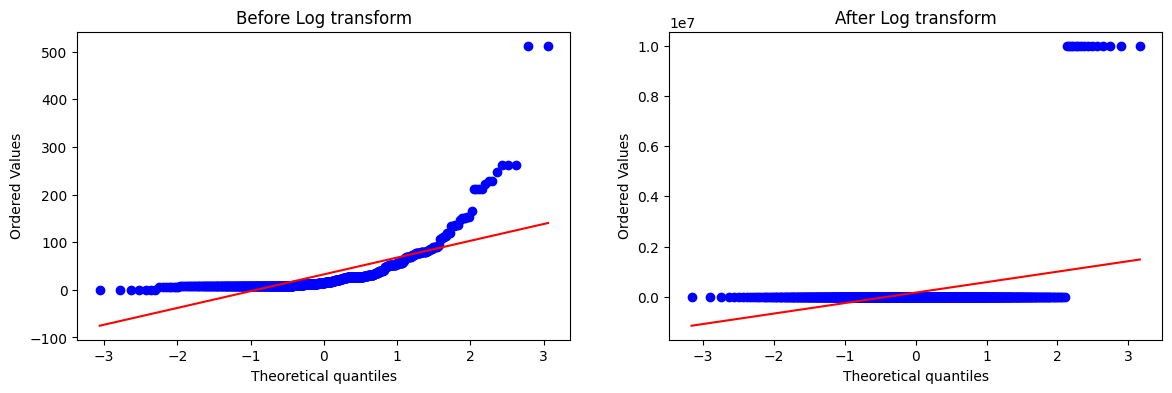

In [43]:
apply_transform(lambda x: 1/(x+0.0000001))

## Square root Transform

Accuracy:  0.6589013732833957


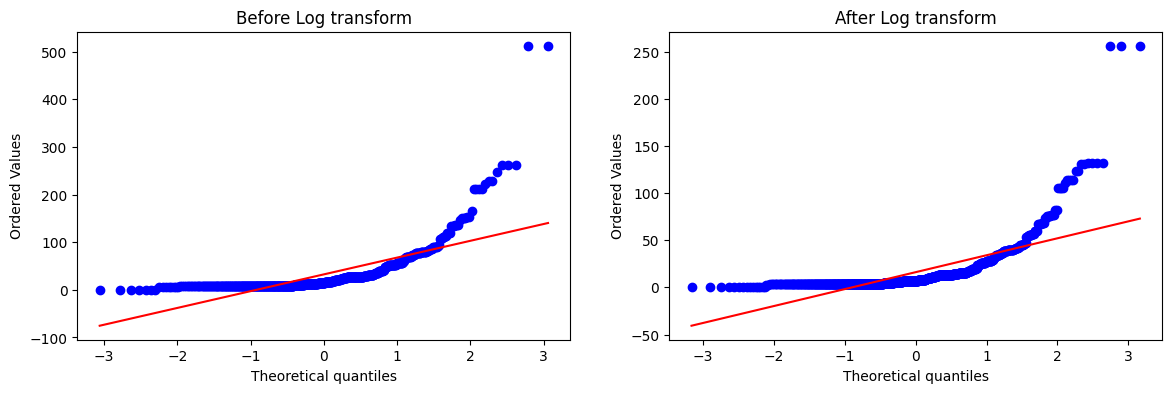

In [44]:
apply_transform(lambda x: x**1/2)

## Square Transform

Accuracy:  0.6431335830212235


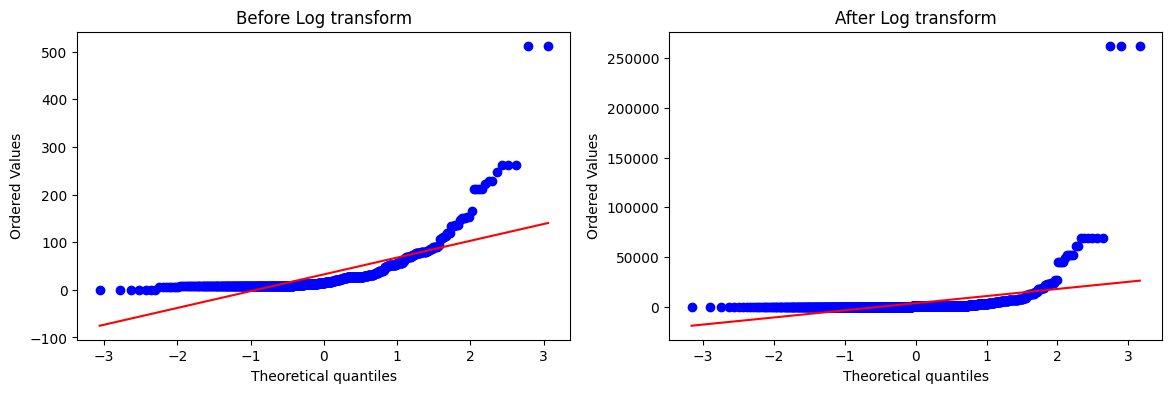

In [45]:
apply_transform(lambda x:x**2)

### Using this function we test different operation like cube root,sine function etc.

Accuracy:  0.6195131086142323


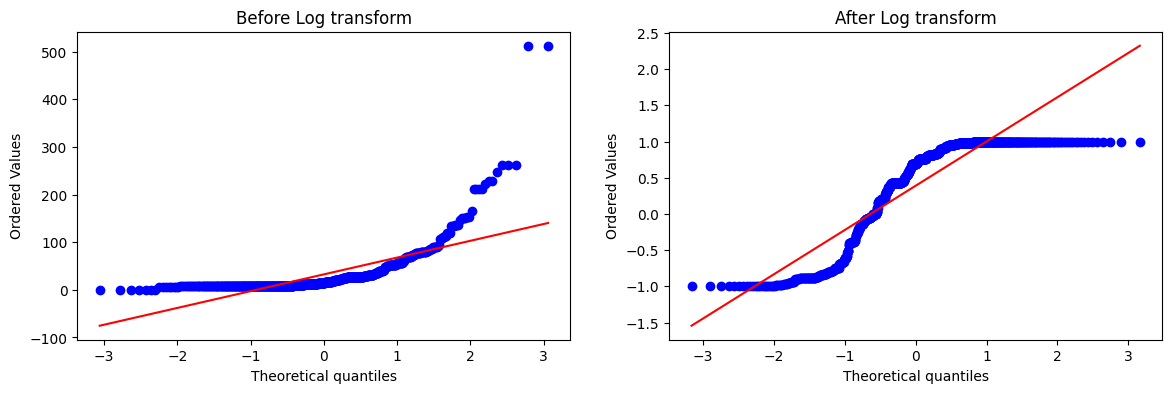

In [46]:
apply_transform(np.sin)

Accuracy:  0.6589013732833957


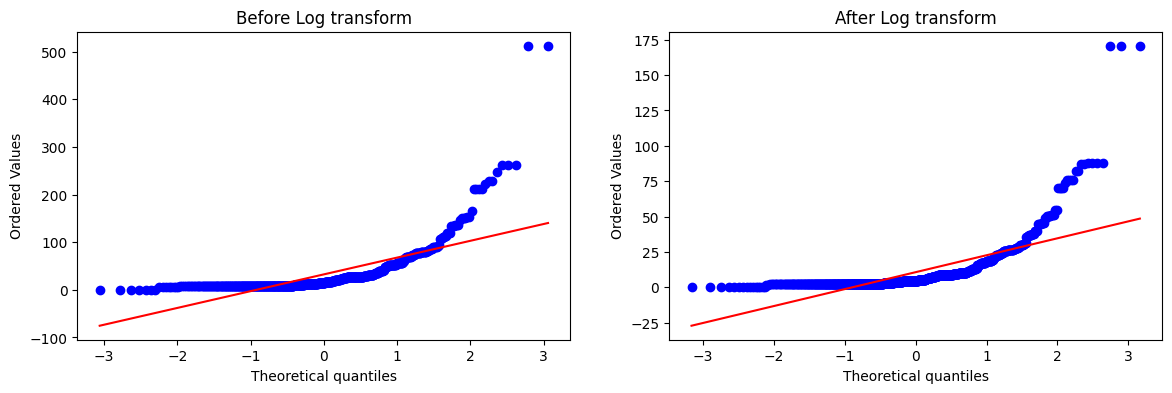

In [47]:
apply_transform(lambda x: x**1/3)